# Task 3 — Bank Marketing Prediction
 1. Problem Framing
The bank wants to predict which clients are likely to say yes to a term deposit.
The bank can call only 10% of clients.
Our goal is to rank clients and select the top 10% with the highest scores.
We will compare different machine learning models and evaluate their performance.

In [1]:
import os
import math
import platform
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
    precision_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 1399
print("Python:", platform.python_version())
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("SEED:", SEED)

Python: 3.13.9
numpy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.7.2
joblib: 1.5.2
SEED: 1399


## 1. Frame the problem
The target is `y`: whether a client says **yes** to the term deposit. The bank can call only **10%** of clients, so the model is mainly a **ranking** model. I use **Average Precision (AP)** as the main cross-validation metric because the positive class is rare and the top of the ranking matters. I also report **ROC-AUC** because it measures ranking quality over all thresholds.

`duration` is in the training file but not in the test file. It is known only after a call happens, so it cannot be used when deciding who to call. `id` is only an identifier. Both are excluded from the model.

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train shape:", train.shape)
print("test shape:", test.shape)
print("Only in train:", sorted(set(train.columns) - set(test.columns)))
print("Only in test:", sorted(set(test.columns) - set(train.columns)))

FEATURES = [c for c in test.columns if c != "id"]
X = train[FEATURES].copy()
y = (train["y"] == "yes").astype(int)
X_test = test[FEATURES].copy()

print("Model features:", len(FEATURES))
print(FEATURES)

train shape: (32940, 22)
test shape: (8236, 20)
Only in train: ['duration', 'y']
Only in test: []
Model features: 19
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## 2. Understand the data
### 2.1 Target balance and the accuracy trap
A majority classifier can get high accuracy only because most clients say no. This is why accuracy is not the main metric.

y
no     29229
yes     3711
Name: count, dtype: int64
y
no     88.73%
yes    11.27%
Name: proportion, dtype: object
Always-no accuracy: 0.8873


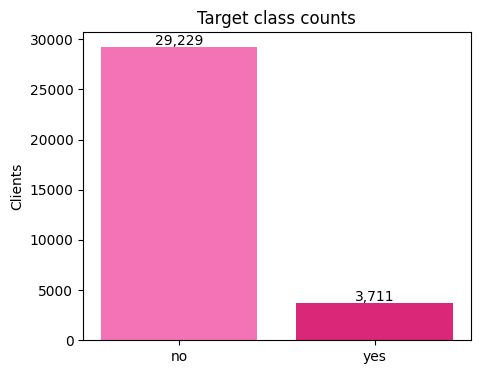

In [23]:
counts = train["y"].value_counts()
rates = train["y"].value_counts(normalize=True)
print(counts)
print((rates * 100).round(2).astype(str) + "%")
print("Always-no accuracy:", round(rates["no"], 4))

plt.figure(figsize=(5, 4))
bars = plt.bar(counts.index, counts.values, color=["#F472B6", "#DB2777"])
plt.title("Target class counts")
plt.ylabel("Clients")
for b, v in zip(bars, counts.values):
    plt.text(b.get_x()+b.get_width()/2, v+200, f"{v:,}", ha="center")
plt.show()

### 2.2 Values that mean missing / not applicable
There are no real `NaN` values. Several categorical columns use the text `unknown`. I keep `unknown` as its own category because the fact that information is missing can itself be useful. I compare this choice against replacing `unknown` by the most frequent category later.

`pdays = 999` is a special sentinel: it means the client was not previously contacted. I treat 999 as missing **inside the pipeline**, impute the median of real `pdays` values, and add a missing indicator. The indicator keeps the important information that this client had no previous contact.

In [4]:
print("Real NaN values:", int(train.isna().sum().sum()))

categorical_cols_all = X.select_dtypes(include="object").columns.tolist()
unknown_counts = {
    c: int((X[c] == "unknown").sum())
    for c in categorical_cols_all
    if (X[c] == "unknown").any()
}
print("'unknown' counts:")
print(pd.Series(unknown_counts).sort_values(ascending=False))

print("pdays = 999:", int((X["pdays"] == 999).sum()))
print("pdays != 999:", int((X["pdays"] != 999).sum()))
print("Share with pdays=999:", round((X["pdays"] == 999).mean(), 4))

Real NaN values: 0
'unknown' counts:
default      6871
education    1401
housing       794
loan          794
job           275
marital        64
dtype: int64
pdays = 999: 31694
pdays != 999: 1246
Share with pdays=999: 0.9622


### 2.3 Row order
The rows look shuffled: months change frequently instead of appearing in long chronological blocks. Therefore I use a **stratified random split** and shuffled stratified CV for this teaching dataset. In real deployment, the model would be trained on the past and tested on a later time period.

In [5]:
month_changes = int((train["month"] != train["month"].shift()).sum())
print("Month changes between adjacent rows:", month_changes, "out of", len(train))
print("First 20 months:", train["month"].head(20).tolist())

Month changes between adjacent rows: 26442 out of 32940
First 20 months: ['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov', 'nov', 'sep', 'aug', 'jul', 'aug', 'nov', 'may', 'apr', 'jun', 'jun']


### 2.4 Features related to the answer
The plots below include numeric rates, not only pictures.

Yes rate by previous campaign outcome (%):
poutcome
success        64.8
failure        14.0
nonexistent     8.8
Name: y, dtype: float64


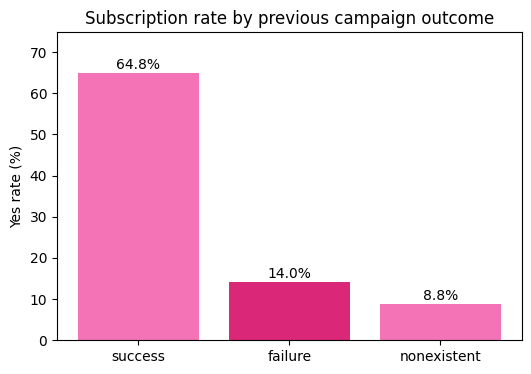

In [24]:
poutcome_rate = train.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
print("Yes rate by previous campaign outcome (%):")
print((poutcome_rate * 100).round(1))

plt.figure(figsize=(6, 4))
bars = plt.bar(poutcome_rate.index, poutcome_rate.values * 100, color=["#F472B6", "#DB2777"])
plt.title("Subscription rate by previous campaign outcome")
plt.ylabel("Yes rate (%)")
for b, v in zip(bars, poutcome_rate.values * 100):
    plt.text(b.get_x()+b.get_width()/2, v+1, f"{v:.1f}%", ha="center")
plt.ylim(0, max(poutcome_rate.values*100) + 10)
plt.show()

Yes rate by contact type (%):
contact
cellular     14.7
telephone     5.3
Name: y, dtype: float64


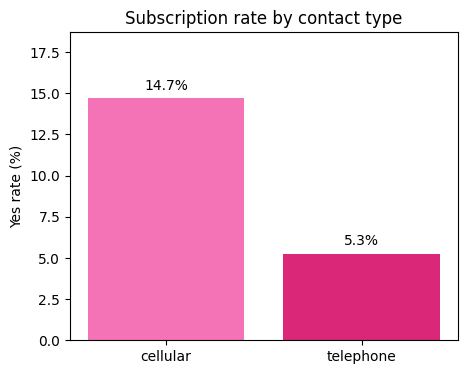

In [25]:
contact_rate = train.groupby("contact")["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
print("Yes rate by contact type (%):")
print((contact_rate * 100).round(1))

plt.figure(figsize=(5, 4))
bars = plt.bar(contact_rate.index, contact_rate.values * 100, color=["#F472B6", "#DB2777"])
plt.title("Subscription rate by contact type")
plt.ylabel("Yes rate (%)")
for b, v in zip(bars, contact_rate.values * 100):
    plt.text(b.get_x()+b.get_width()/2, v+0.5, f"{v:.1f}%", ha="center")
plt.ylim(0, max(contact_rate.values*100) + 4)
plt.show()

**Numeric observations:** previous campaign `success` has a much higher yes rate than `nonexistent`. Cellular contact also has a higher yes rate than telephone. These are associations, not proof of causation.

## 3. Validation design
I keep **20% of train.csv as a final hold-out** and do not use it for model choice. All preprocessing comparisons, baselines, model comparisons and tuning use only the remaining 80% with **3-fold StratifiedKFold**. Stratification keeps the yes/no ratio similar in every fold.

In [ ]:
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print("Development rows:", len(X_dev))
print("Hold-out rows:", len(X_hold))
print("Development positive rate:", round(y_dev.mean(), 4))
print("Hold-out positive rate:", round(y_hold.mean(), 4))

Development rows: 26352
Hold-out rows: 6588
Development positive rate: 0.1127
Hold-out positive rate: 0.1126


## 4. Preprocessing inside a Pipeline
Every operation that learns from data is inside `Pipeline` / `ColumnTransformer`, so during cross-validation it is fitted only on the training fold.

- normal numeric columns: `StandardScaler`
- `pdays`: treat `999` as missing, median imputation + missing indicator + scaling
- categorical columns: one-hot encoding with unseen-category protection

This saved pipeline accepts raw test columns directly, with no manual preprocessing.

In [9]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols and c != "pdays"]


def build_preprocessor(cat_mode="keep"):
    if cat_mode == "keep":
        cat_pipe = Pipeline([
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
        ])
    elif cat_mode == "impute_unknown":
        cat_pipe = Pipeline([
            ("unknown_imputer", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
        ])
    else:
        raise ValueError("Unknown cat_mode")

    num_pipe = Pipeline([
        ("scale", StandardScaler())
    ])

    pdays_pipe = Pipeline([
        ("sentinel_imputer", SimpleImputer(
            missing_values=999,
            strategy="median",
            add_indicator=True
        )),
        ("scale", StandardScaler())
    ])

    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("pdays", pdays_pipe, ["pdays"]),
        ("cat", cat_pipe, cat_cols)
    ])

preprocessor = build_preprocessor("keep")
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['age', 'campaign', 'previous', 'emp.var.rate',
                                  'cons.price.idx', 'cons.conf.idx',
                                  'euribor3m', 'nr.employed']),
                                ('pdays',
                                 Pipeline(steps=[('sentinel_imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                missing_values=999,
                                                                strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['pdays']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unkno

### 4.1 One preprocessing choice vs an alternative
I compare keeping `unknown` as a category against replacing it with the most frequent category. Same folds, same Logistic Regression, same metric.

In [10]:
prep_rows = []
for mode in ["keep", "impute_unknown"]:
    pipe = Pipeline([
        ("preprocess", build_preprocessor(mode)),
        ("model", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))
    ])
    r = cross_validate(
        pipe, X_dev, y_dev, cv=cv,
        scoring={"ap": "average_precision", "auc": "roc_auc"},
        n_jobs=1
    )
    prep_rows.append({
        "categorical_missing_strategy": mode,
        "AP_mean": r["test_ap"].mean(),
        "AP_std": r["test_ap"].std(),
        "ROC_AUC_mean": r["test_auc"].mean(),
        "ROC_AUC_std": r["test_auc"].std()
    })

prep_results = pd.DataFrame(prep_rows)
display(prep_results.round(4))
print("The difference is very small compared with fold spread, so I keep 'unknown' as an explicit category.")

,categorical_missing_strategy,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std
0,keep,0.4513,0.0040,0.7935,0.0102
1,impute_unknown,0.4513,0.0037,0.7931,0.0112


The difference is very small compared with fold spread, so I keep 'unknown' as an explicit category.


## 5. Baselines
The majority baseline shows why accuracy is misleading. Logistic Regression is the simple model baseline that later models must beat.

In [11]:
scoring = {"ap": "average_precision", "auc": "roc_auc", "acc": "accuracy"}

# Majority-class baseline
majority = DummyClassifier(strategy="most_frequent")
r_dummy = cross_validate(majority, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=1)

# Simple model baseline
simple_logreg = Pipeline([
    ("preprocess", build_preprocessor("keep")),
    ("model", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))
])
r_log = cross_validate(simple_logreg, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=1)

baseline_results = pd.DataFrame([
    {
        "model": "Majority (always no)",
        "AP_mean": r_dummy["test_ap"].mean(), "AP_std": r_dummy["test_ap"].std(),
        "ROC_AUC_mean": r_dummy["test_auc"].mean(), "ROC_AUC_std": r_dummy["test_auc"].std(),
        "Accuracy_mean": r_dummy["test_acc"].mean(), "Accuracy_std": r_dummy["test_acc"].std()
    },
    {
        "model": "Logistic Regression",
        "AP_mean": r_log["test_ap"].mean(), "AP_std": r_log["test_ap"].std(),
        "ROC_AUC_mean": r_log["test_auc"].mean(), "ROC_AUC_std": r_log["test_auc"].std(),
        "Accuracy_mean": r_log["test_acc"].mean(), "Accuracy_std": r_log["test_acc"].std()
    }
])
display(baseline_results.round(4))

,model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std
0,Majority (always no),0.1127,0.0001,0.5000,0.0000,0.8873,0.0001
1,Logistic Regression,0.4513,0.0040,0.7935,0.0102,0.8988,0.0003


## 6. Compare model families on the same folds
I compare three model families taught in the course. All use the same preprocessing and the same three folds.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    "Linear SVM": LinearSVC(C=1.0, random_state=SEED)
}

model_rows = []
for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocess", build_preprocessor("keep")),
        ("model", estimator)
    ])
    r = cross_validate(
        pipe, X_dev, y_dev, cv=cv,
        scoring={"ap": "average_precision", "auc": "roc_auc"},
        n_jobs=1
    )
    model_rows.append({
        "model": name,
        "AP_mean": r["test_ap"].mean(),
        "AP_std": r["test_ap"].std(),
        "ROC_AUC_mean": r["test_auc"].mean(),
        "ROC_AUC_std": r["test_auc"].std()
    })

model_results = pd.DataFrame(model_rows).sort_values("AP_mean", ascending=False).reset_index(drop=True)
display(model_results.round(4))

,model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression,0.4513,0.004,0.7935,0.0102
1,Linear SVM,0.4472,0.004,0.7897,0.0101
2,Decision Tree,0.4175,0.005,0.7768,0.0094


### Interpretation of fold spread
A model with a slightly larger mean is not automatically a real winner. I compare the mean difference with the fold standard deviations. If the difference is about the same size as the fold spread, I treat the result as uncertain.

In [13]:
best = model_results.iloc[0]
log_row = model_results[model_results["model"] == "Logistic Regression"].iloc[0]
print("Highest mean AP model:", best["model"])
print("AP difference vs Logistic Regression:", round(float(best["AP_mean"] - log_row["AP_mean"]), 4))
print("Best model AP fold std:", round(float(best["AP_std"]), 4))
print("Logistic AP fold std:", round(float(log_row["AP_std"]), 4))
print("Conclusion: if the difference is inside this spread, I do not call it a clear win.")

Highest mean AP model: Logistic Regression
AP difference vs Logistic Regression: 0.0
Best model AP fold std: 0.004
Logistic AP fold std: 0.004
Conclusion: if the difference is inside this spread, I do not call it a clear win.


## 6.1 Tune Logistic Regression and test class weighting
Search space:
- `C`: 0.2, 1.0, 5.0
- `class_weight`: `None` or `balanced`

The search uses only the development data and the same stratified folds. This also directly tests whether class-imbalance weighting helps.

In [14]:
log_pipe = Pipeline([
    ("preprocess", build_preprocessor("keep")),
    ("model", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))
])

param_grid = {
    "model__C": [0.2, 1.0, 5.0],
    "model__class_weight": [None, "balanced"]
}

search = GridSearchCV(
    log_pipe,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=False
)
search.fit(X_dev, y_dev)

search_results = pd.DataFrame(search.cv_results_)[[
    "param_model__C", "param_model__class_weight",
    "mean_test_score", "std_test_score"
]].sort_values("mean_test_score", ascending=False)

display(search_results.round(4))
print("Best parameters:", search.best_params_)
print("Best CV AP:", round(search.best_score_, 4))

,param_model__C,param_model__class_weight,mean_test_score,std_test_score
4,5.0,None,0.4515,0.0035
2,1.0,None,0.4513,0.0040
0,0.2,None,0.4507,0.0047
5,5.0,balanced,0.4474,0.0059
3,1.0,balanced,0.4471,0.0059
1,0.2,balanced,0.4460,0.0072


Best parameters: {'model__C': 5.0, 'model__class_weight': None}
Best CV AP: 0.4515


**Model choice:** I use tuned Logistic Regression for the final model. Linear SVM is close, but the AP difference is much smaller than the fold-to-fold spread, so I do not call Logistic Regression a statistically clear winner. I choose it because it gives probabilities directly, is small, stable and easy to explain. The class-balanced version does not improve AP, so I do not use it.

## 7. Final evaluation on the hold-out — once
Now all choices are finished. I fit the chosen pipeline on the development part and evaluate the untouched hold-out one time.

In [15]:
chosen_model = search.best_estimator_
chosen_model.fit(X_dev, y_dev)

hold_score = chosen_model.predict_proba(X_hold)[:, 1]
hold_auc = roc_auc_score(y_hold, hold_score)
hold_ap = average_precision_score(y_hold, hold_score)

print("Hold-out ROC-AUC:", round(hold_auc, 4))
print("Hold-out Average Precision:", round(hold_ap, 4))

Hold-out ROC-AUC: 0.7783
Hold-out Average Precision: 0.4534


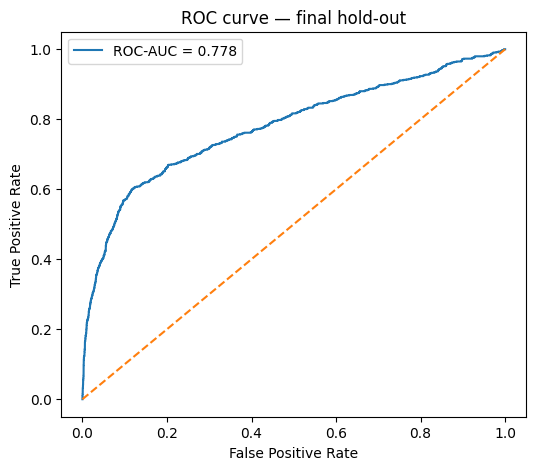

In [16]:
fpr, tpr, _ = roc_curve(y_hold, hold_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {hold_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve — final hold-out")
plt.legend()
plt.show()

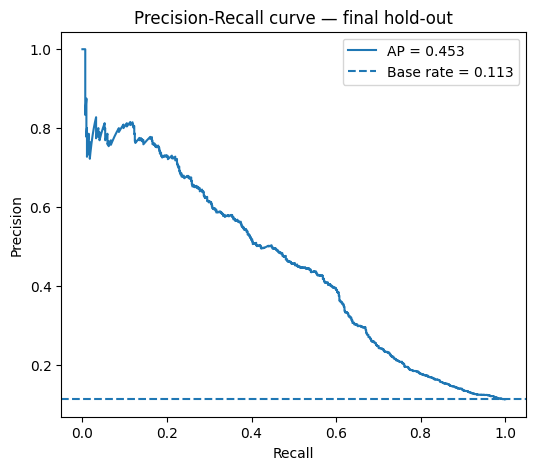

In [17]:
pr_precision, pr_recall, _ = precision_recall_curve(y_hold, hold_score)
plt.figure(figsize=(6, 5))
plt.plot(pr_recall, pr_precision, label=f"AP = {hold_ap:.3f}")
plt.axhline(y_hold.mean(), linestyle="--", label=f"Base rate = {y_hold.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve — final hold-out")
plt.legend()
plt.show()

### 7.1 Apply the 10% call-centre capacity rule
I do not use the usual 0.5 probability cutoff. I sort clients by score and call only the top 10%. The cutoff is therefore determined by capacity.

In [18]:
n_call = int(np.floor(0.10 * len(y_hold)))
order = np.argsort(-hold_score)
call_pred = np.zeros(len(y_hold), dtype=int)
call_pred[order[:n_call]] = 1
capacity_cutoff = float(hold_score[order[n_call - 1]])

precision_10 = precision_score(y_hold, call_pred, zero_division=0)
recall_10 = recall_score(y_hold, call_pred, zero_division=0)
base_rate = float(y_hold.mean())
lift_10 = precision_10 / base_rate
cm = confusion_matrix(y_hold, call_pred)

tn, fp, fn, tp = cm.ravel()
print("Clients in hold-out:", len(y_hold))
print("Clients called:", n_call, f"({100*n_call/len(y_hold):.2f}%)")
print("Capacity cutoff:", round(capacity_cutoff, 4))
print("Precision @ top 10%:", round(precision_10, 4))
print("Recall @ top 10%:", round(recall_10, 4))
print("Random-call positive rate:", round(base_rate, 4))
print("Lift over random calling:", round(lift_10, 2), "x")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print()
print(f"Manager reading: we call {n_call} clients. {tp} of them say yes and {fp} say no.")
print(f"We do not call {tn+fn} clients; among them, {fn} would have said yes.")

Clients in hold-out: 6588
Clients called: 658 (9.99%)
Capacity cutoff: 0.3151
Precision @ top 10%: 0.5015
Recall @ top 10%: 0.4447
Random-call positive rate: 0.1126
Lift over random calling: 4.45 x
Confusion matrix [[TN, FP], [FN, TP]]:
[[5518  328]
 [ 412  330]]

Manager reading: we call 658 clients. 330 of them say yes and 328 say no.
We do not call 5930 clients; among them, 412 would have said yes.


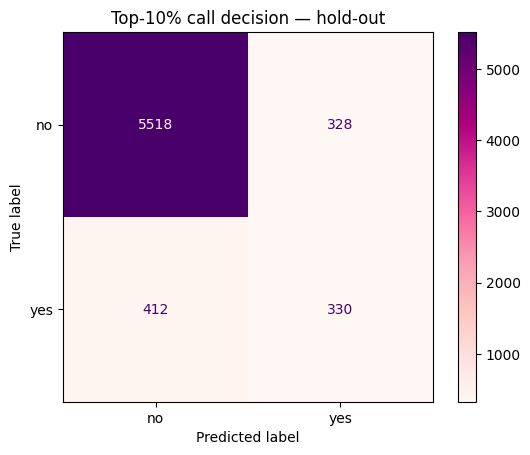

In [26]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["no", "yes"]
).plot(
    values_format="d",
    cmap="RdPu"
)
plt.title("Top-10% call decision — hold-out")
plt.show()

### 7.2 Limitation of the random split
This teaching split is random, but real use is temporal: train on older campaigns and call clients in a future campaign. A random split mixes similar time periods into train and validation, so it can make performance look better than future deployment. Economic conditions, campaign design and client behaviour can change over time. A stronger real-world test would use an out-of-time split.

## 8. Refit on all training data, save the pipeline, score test.csv
The final pipeline is refitted on all labelled rows. `model.joblib` receives raw test features directly. `predictions.csv` uses the same 10% capacity rule on the hidden test list.

In [20]:
final_model = Pipeline([
    ("preprocess", build_preprocessor("keep")),
    ("model", LogisticRegression(
        C=search.best_params_["model__C"],
        class_weight=search.best_params_["model__class_weight"],
        max_iter=1000,
        solver="liblinear",
        random_state=SEED
    ))
])
final_model.fit(X, y)

joblib.dump(final_model, "model.joblib")

test_score = final_model.predict_proba(X_test)[:, 1]
test_n_call = int(np.floor(0.10 * len(test)))
test_order = np.argsort(-test_score)
test_pred = np.zeros(len(test), dtype=int)
test_pred[test_order[:test_n_call]] = 1

predictions = pd.DataFrame({
    "id": test["id"].values,
    "y_pred": test_pred,
    "y_score": test_score
})
predictions.to_csv("predictions.csv", index=False)

print("model.joblib size (MB):", round(os.path.getsize("model.joblib") / 1024**2, 3))
print("predictions shape:", predictions.shape)
print("called clients:", int(predictions["y_pred"].sum()))
print("call share:", round(predictions["y_pred"].mean(), 4))
display(predictions.head())

model.joblib size (MB): 0.008
predictions shape: (8236, 3)
called clients: 823
call share: 0.0999


,id,y_pred,y_score
0,32940,0,0.070827
1,32941,0,0.032299
2,32942,0,0.044188
3,32943,0,0.057068
4,32944,0,0.024911


## 8.1 Smoke test the saved model
This checks that the saved object can be loaded and can score raw test columns. Before submission I also run the fresh-process command from the task handout in the repository root.

In [21]:
loaded_model = joblib.load("model.joblib")
smoke_scores = loaded_model.predict_proba(test[FEATURES].head(5))[:, 1]
print("Loaded model scores:", smoke_scores)
print("Required prediction columns:", predictions.columns.tolist())
print("Unique y_pred values:", sorted(predictions["y_pred"].unique().tolist()))
print("All test IDs present:", predictions["id"].equals(test["id"]))

Loaded model scores: [0.07082682 0.03229861 0.04418769 0.05706791 0.02491093]
Required prediction columns: ['id', 'y_pred', 'y_score']
Unique y_pred values: [0, 1]
All test IDs present: True
